# Milestone 2 — hh-rlhf data pipeline (v1.1)

Run the cells **top to bottom**. Each pipeline step is a separate script in `src/`; its docstring states the input, output and rules.

**Before you start** (one-off): add a Colab Secret — key icon 🔑 in the left sidebar → *Add new secret* → Name `DHAI_BUCKET`, Value = your bucket name (e.g. `bc-rlhf-reward-2026`) → switch on *Notebook access*.

## 0. Settings — edit these two lines

In [1]:
# Settings used by the cells below.
GITHUB_REPO = "bounchun/rlhf-reward-model-pipeline-m2"   # <- your GitHub user/repo
GCP_PROJECT = "rlhf-reward-pipeline-bc"              # <- Google Cloud console, project picker at the top

In [2]:
# Download the code from GitHub and install the pinned libraries (exact versions from requirements.txt).
!git clone https://github.com/{GITHUB_REPO}.git repo
%cd repo
!pip install -q -r requirements.txt

Cloning into 'repo'...
remote: Enumerating objects: 956, done.
remote: Counting objects: 100% (136/136), done.
remote: Compressing objects: 100% (73/73), done.
remote: Total 956 (delta 100), reused 63 (delta 63), pack-reused 820 (from 2)
Receiving objects: 100% (956/956), 7.89 MiB | 13.67 MiB/s, done.
Resolving deltas: 100% (566/566), done.
/content/repo


In [3]:
# Log in to Google Cloud (no key files; also used by the gcloud CLI below)
from google.colab import auth, userdata
auth.authenticate_user()
!gcloud config set project {GCP_PROJECT}

# Read the bucket name from Colab Secrets, so it is never written in the code.
import os
os.environ['DHAI_BUCKET'] = userdata.get('DHAI_BUCKET')   # bucket name from Colab Secrets
print('Bucket:', os.environ['DHAI_BUCKET'])

Updated property [core/project].
Bucket: bc-rlhf-reward-2026


## 0b. Create the buckets — ONE-OFF, skip if they already exist
Creates `<bucket>` (Standard) and `<bucket>-holdout` (Coldline) in europe-west1 with versioning, lifecycle rules and two service accounts.

In [ ]:
# One-off: create the main bucket (Standard) and the holdout bucket (Coldline),
# with versioning, clean-up rules and the two service accounts. Skip if they already exist.
!PROJECT={GCP_PROJECT} BUCKET={os.environ['DHAI_BUCKET']} bash scripts/setup_gcs.sh

## Optional: check everything offline first
Tests + a full demo on synthetic data (no GCS, no Hugging Face). Should end with `OK`.

In [ ]:
# Offline check (no Google Cloud, no Hugging Face):
# 1) the 43 unit tests, which should end with "OK";
# 2) the whole pipeline on fake data, which should print "demo OK".
!make test 2>&1 | tail -3
!DHAI_BUCKET= make demo > /dev/null && make clean-demo && echo 'demo OK'

## Pin the dataset version (skip: already pinned)
`config.json` is already pinned to commit `09be8c5bbc57cb3887f3a9732ad6aa7ec602a1fa`, so **skip this cell** for a normal run.
Only run it to move to a newer revision of the dataset: it rewrites `config.json`, so the same change must then be committed to GitHub, or the manifest will record a `-dirty` commit.

In [ ]:
# SKIP for a normal run: config.json is already pinned.
# Only for moving to a newer dataset version: ask Hugging Face for the latest commit hash
# and write it into config.json (then commit the same change to GitHub).
import json, subprocess
rev = subprocess.check_output(['python', '-m', 'src.step1_scrape_raw', '--resolve-revision'], text=True).strip()
cfg = json.load(open('config.json'))
cfg['dataset']['hf_revision'] = rev
json.dump(cfg, open('config.json', 'w'), indent=2, ensure_ascii=False)
print('Pinned hf_revision =', rev)

## Step 1 — scrape the raw data
Downloads the 8 raw files at the pinned revision and records their SHA-256 checksums.

In [4]:
# Step 1: download the 8 raw files at the pinned commit and save their SHA-256 checksums.
# Output: data/downloads/<commit>/ and manifests/raw-<commit>.json
!python -m src.step1_scrape_raw

  helpful-base/train.jsonl.gz                     16.20 MB  sha256=518a5bf28845…
  helpful-base/test.jsonl.gz                       0.88 MB  sha256=8be3fc1a13b2…
  harmless-base/train.jsonl.gz                    13.20 MB  sha256=bf3e1ecd3db6…
  harmless-base/test.jsonl.gz                      0.74 MB  sha256=ebfaaed21162…
  helpful-online/train.jsonl.gz                   20.13 MB  sha256=0994d18b8208…
  helpful-online/test.jsonl.gz                     1.05 MB  sha256=39a475cc7e0d…
  helpful-rejection-sampled/train.jsonl.gz        25.70 MB  sha256=0cea2d2ab218…
  helpful-rejection-sampled/test.jsonl.gz          1.36 MB  sha256=abc35dbc5601…
Downloaded 8 files -> /content/repo/data/downloads/09be8c5bbc57cb3887f3a9732ad6aa7ec602a1fa
Raw manifest -> /content/repo/manifests/raw-09be8c5bbc57cb3887f3a9732ad6aa7ec602a1fa.json


## Step 2 — move the raw data into storage
Uploads to `gs://<bucket>/raw/hh-rlhf/<revision>/` (write-once, read-back verified).

In [5]:
# Step 2: upload the raw files to gs://<bucket>/raw/, read them back to check them.
# raw/ is write-once: a file with different content is never overwritten.
!python -m src.step2_store_raw

  helpful-base/train.jsonl.gz                   already stored (verified)
  helpful-base/test.jsonl.gz                    already stored (verified)
  harmless-base/train.jsonl.gz                  already stored (verified)
  harmless-base/test.jsonl.gz                   already stored (verified)
  helpful-online/train.jsonl.gz                 already stored (verified)
  helpful-online/test.jsonl.gz                  already stored (verified)
  helpful-rejection-sampled/train.jsonl.gz      already stored (verified)
  helpful-rejection-sampled/test.jsonl.gz       already stored (verified)
Raw data stored at gs://bc-rlhf-reward-2026/raw/hh-rlhf/09be8c5bbc57cb3887f3a9732ad6aa7ec602a1fa


## Step 3 — validate and clean

In [6]:
# Step 3: check the raw checksums again, then apply the 5 cleaning rules.
# Prints how many rows each rule dropped. Output: data/interim/<version>/cleaned.parquet
!python -m src.step3_clean

Counters:
  rows_read                     169,352
  rows_kept                     168,029
  rows_quarantined                1,323
    context_mismatch                329
    empty_reply                     194
    identical_after_pii_mask          1
    identical_replies               788
    malformed_turns:chosen            2
    malformed_turns:rejected          9
  pairs with PII masked        {"email": 304, "phone": 724}
Kept 168,029 pairs -> /content/repo/data/interim/v1.1/cleaned.parquet
Quarantine (1,323 rows, with reasons) -> gs://bc-rlhf-reward-2026/quarantine/v1.1/quarantine.parquet


## Step 4 — quality checks (poisoning screen, PII, lengths)

In [7]:
# Step 4: hard checks (the run stops if one fails), poisoning screen, PII scan, length summary.
# Output: gs://<bucket>/audit/<version>/
!python -m src.step4_quality_checks

Validation passed: {'pair_id_unique': True, 'no_empty_replies': True, 'no_identical_replies': True, 'known_subsets_only': True, 'no_nulls': True, 'no_residual_pii_after_masking': True}
Poison screen: 0 one-sided n-grams in 0 pairs (flag only) -> gs://bc-rlhf-reward-2026/audit/v1.1
PII: email=0, phone=0


## Step 5 — extract features

In [8]:
# Step 5: add group_id, swap A/B to balance the labels, and add the length and refusal columns.
# Output: data/interim/<version>/features.parquet
!python -m src.step5_features

Features for 168,029 pairs, 61,961 groups (0 pairs re-keyed) -> /content/repo/data/interim/v1.1/features.parquet


## Step 6 — reserve future data, filter to the working set

In [9]:
# Step 6: set aside the future data (F1, F2), then take the ~30k working set in whole groups.
!python -m src.step6_filter

Working set 30,002 pairs (target 30,000); future reserve 33,168; unused pool 104,859


## Step 7 — train / dev / test split

In [10]:
# Step 7: split the working set into train/dev/test (80/10/10) by conversation group,
# check that no group is in two splits, and fit the length-outlier threshold on train only.
!python -m src.step7_split

  train       24,122 pairs
  dev          2,876 pairs
  test         3,004 pairs
  future_f1   16,516 pairs
  future_f2   16,652 pairs
Long-outlier threshold (train only): 210.0 words


## Step 8 — sharding (off by default)

In [11]:
# Step 8: optional training shards. Off by default (num_shards = 1 in config.json),
# so this only prints that it was skipped.
!python -m src.step8_shard

Sharding disabled (shards.num_shards <= 1) - see README section 2.


## Step 9 — store the preprocessed data

In [12]:
# Step 9: final checks, then upload train/dev to gs://<bucket>/processed/<version>/
# and test/F1/F2 to the holdout bucket, with their checksums in the manifest.
!python -m src.step9_store_processed

  data contract: 17 rules x 5 splits passed -> gs://bc-rlhf-reward-2026/audit/v1.1/validation_log.csv
  train       24,122 pairs -> gs://bc-rlhf-reward-2026/processed/v1.1/train.parquet
  dev          2,876 pairs -> gs://bc-rlhf-reward-2026/processed/v1.1/dev.parquet
  test         3,004 pairs -> gs://bc-rlhf-reward-2026-holdout/v1.1/test.parquet
  future_f1   16,516 pairs -> gs://bc-rlhf-reward-2026-holdout/v1.1/future_f1.parquet
  future_f2   16,652 pairs -> gs://bc-rlhf-reward-2026-holdout/v1.1/future_f2.parquet
Manifest -> /content/repo/manifests/v1.1.json (commit this file) and gs://bc-rlhf-reward-2026/manifests


## Step 10 — blind human-review sample

In [13]:
# Step 10: export 200 train pairs, without labels, for checking the labels by hand.
# Output: audit/label_review_v1.1.csv (stays local, never committed to Git)
!python -m src.step10_review_sample

Review sheet: written -> /content/repo/audit/label_review_v1.1.csv


## Step 11 — model-ready inputs (Milestone 2)
Text inputs with left-truncated contexts and log-length features standardised with the **train** mean/SD. Train/dev go to `processed/<version>/model_inputs/`, test/F1/F2 to the holdout bucket.

In [14]:
# Step 11: build model-ready inputs; the scaler is fitted on train only and applied to every split.
!python -m src.step11_model_inputs

  train       24,122 rows  truncated contexts   9.7%  -> gs://bc-rlhf-reward-2026/processed/v1.1/model_inputs/train.parquet
  dev          2,876 rows  truncated contexts   8.3%  -> gs://bc-rlhf-reward-2026/processed/v1.1/model_inputs/dev.parquet
  test         3,004 rows  truncated contexts   9.5%  -> gs://bc-rlhf-reward-2026-holdout/v1.1/model_inputs/test.parquet
  future_f1   16,516 rows  truncated contexts   9.9%  -> gs://bc-rlhf-reward-2026-holdout/v1.1/model_inputs/future_f1.parquet
  future_f2   16,652 rows  truncated contexts   9.8%  -> gs://bc-rlhf-reward-2026-holdout/v1.1/model_inputs/future_f2.parquet
Scaler fitted on 24,122 train rows -> gs://bc-rlhf-reward-2026/processed/v1.1/model_inputs/numeric_scaler.json


## Reconciliation — a second, independent method (Milestone 2)
Recounts the raw files with plain Python and compares them with what the pipeline stored. Should end with `All 7 checks agree`.

In [15]:
# Independent recount: raw rows, row accounting, checksums, label direction, split overlap.
!python -m src.reconcile

  AGREE    R1 raw rows recounted from the raw files: pipeline 169352 | independent 169352
  AGREE    R2 rows_read = cleaned + quarantined: pipeline 169352 | independent 169352
  AGREE    R4 stored files match their manifest SHA-256: pipeline {'train': True, 'dev': True, 'test': True, 'future_f1': True, 'future_f2': True} | independent {'train': True, 'dev': True, 'test': True, 'future_f1': True, 'future_f2': True}
  AGREE    R4 stored row counts match the manifest: pipeline {'train': 24122, 'dev': 2876, 'test': 3004, 'future_f1': 16516, 'future_f2': 16652} | independent {'train': 24122, 'dev': 2876, 'test': 3004, 'future_f1': 16516, 'future_f2': 16652}
  AGREE    R3 cleaned = stored splits + unused pool: pipeline 168029 | independent 168029
  AGREE    R5 preferred reply is the raw `chosen` reply (stored pairs not matched): pipeline 0 | independent 0
  AGREE    R6 pair_id / group_id in two splits: pipeline {'pairs': 0, 'groups': 0} | independent {'pairs': 0, 'groups': 0}
All 7 checks ag

## EDA (Milestone 2)
Writes 9 figures, `eda_summary.json` and `findings.csv` to `docs/eda/`. Distributions use **train only**; the holdout bucket is never read. Takes a few minutes (the reply-similarity step).

In [16]:
# EDA on the real data. Outputs: docs/eda/fig1..fig9, eda_summary.json, findings.csv
!python -m src.eda
import pandas as pd
pd.set_option('display.max_colwidth', 200)
pd.read_csv('docs/eda/findings.csv')

E1 raw-data problems ...
E2 duplicates, groups and leakage ...
E3 distributions (train) ...
E4 length vs preference (train) ...
E5 refusals (train) ...
E8 shortcut baselines (train -> dev) ...
E9 feature-feature relationships (train) ...
E10 inference: group bootstrap, dev confirmation, multiple testing, precision (Week 4) ...
E11 cross-validation: random-row vs prompt-group folds (Lecture 5) ...

13 findings -> /content/repo/docs/eda/findings.csv
Summary -> /content/repo/docs/eda/eda_summary.json
  figure fig1_quarantine_by_subset.png
  figure fig2_groups_and_similarity.png
  figure fig3_length_distributions.png
  figure fig4_length_bias.png
  figure fig5_length_baselines_dev.png
  figure fig6_refusals.png
  figure fig7_feature_correlations.png
  figure fig8_inference.png
  figure fig9_cross_validation.png


,finding,decision,limitation
0,Position leak: in the raw files the preferred reply is always `chosen` (label would be 100% one class),Swap A/B by hash(pair_id) in step 5; label share is now 49.8% in train,None (deterministic and checked)
1,"Rule violations differ by subset (quarantine rate: chi2 p = 5.6e-65, Cramer's V = 0.042): 'missingness' is not MCAR",Quarantine with reason + source line (not silent drop); report quarantine rate per subset every run,Rates are small; the reason why subsets differ (collection process) cannot be tested from the data
2,93% of pairs share their opening prompt; 92.2% of official test pairs have their prompt in official train,Keep the group split (step 7) instead of the official split; contract rule 'no group_id in two splits',Grouping on the first turn cannot catch paraphrased prompts
3,0.2% of train pairs have near-identical replies (similarity >= 0.9),Keep them (real comparisons) but add an evaluation slice for near-identical pairs in M3,Labels on almost-equal replies are the noisiest; they cap achievable accuracy
4,Reply length is right-skewed (skew 2.02 -> -0.39 after log1p); the 1.5 IQR fence would flag 5.0% of replies,Flag (not delete) replies above the train 99th percentile; use log1p lengths for numeric features,Long replies are valid data; flagging is only for evaluation slices
5,"Inputs are related: reply A vs B length rho = 0.50, turns vs context words rho = 0.82",Use the log length ratio (step 11) rather than two raw lengths for linear baselines; keep both for slices,Spearman captures monotonic links only
6,Rows are clustered in prompt groups: resampling groups instead of rows inflates the variance of the length-bias estimates (median design effect 1.085); the effect still holds and replicates on hel...,"Report group-bootstrap intervals (resampling prompt groups) for M3 test accuracy, not row-level intervals",Per-subset test accuracy will only be known to about +/-5%
7,"Random-row and prompt-group 5-fold CV agree (gap 0.2%) for the length x subset and bag-of-words models; group folds vary more between folds; dev: length x subset 57.9%, bag of words, reply A - rep...",Use GroupKFold for any cross-validation in M3; the bag-of-words model is the first text baseline,"No measurable inflation for these reply-only models; this does not prove leakage is absent, and a model that reads the prompt could still memorise it"
8,9.7% of train contexts exceed 256 words,"Model inputs keep the last 256 words of the context (step 11, left truncation)",Early turns are lost for long conversations
9,The longer reply is preferred in 58.2% of helpful-base pairs and 42.1% of harmless-base pairs (Cramer's V = 0.144; opposite sides of 50%); pooled: 51.8%,Length is a shortcut: never report pooled accuracy alone; evaluate per subset and per length-gap slice,"Association, not causation: length may stand for informativeness or for refusing"


**fig1_quarantine_by_subset.png**

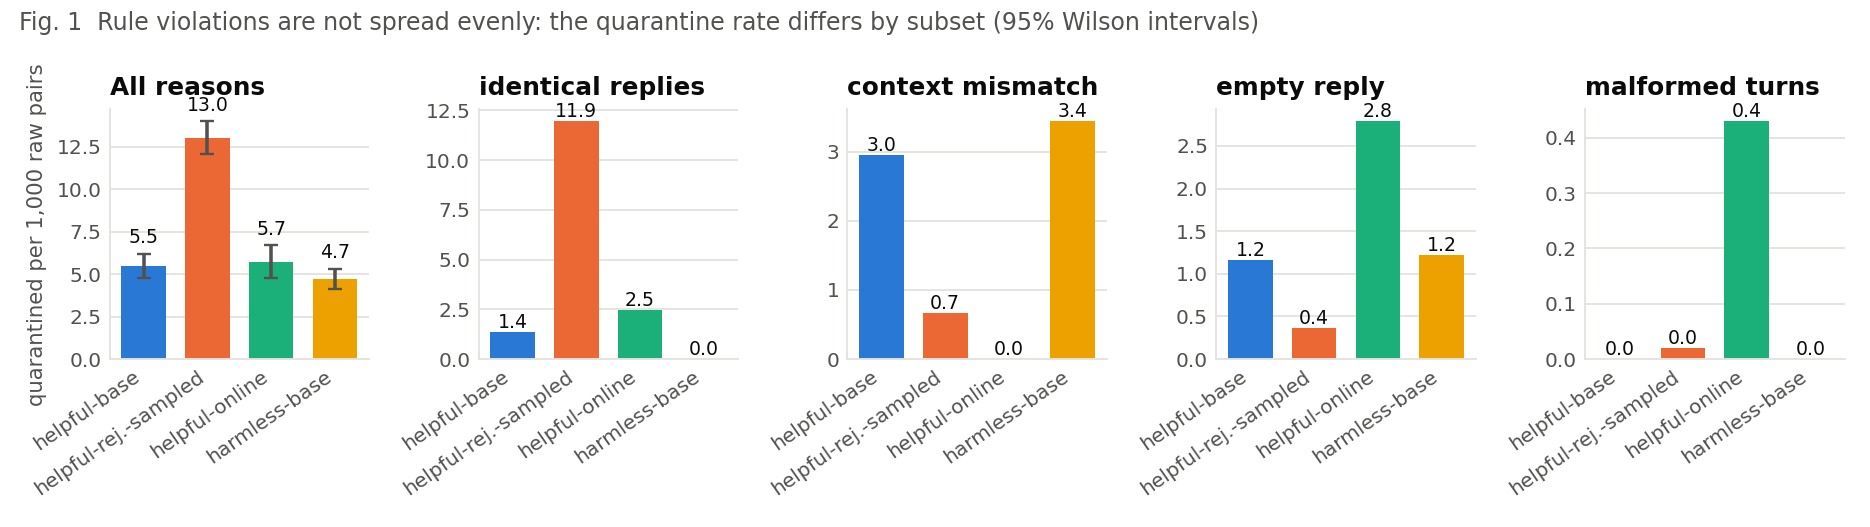

**fig2_groups_and_similarity.png**

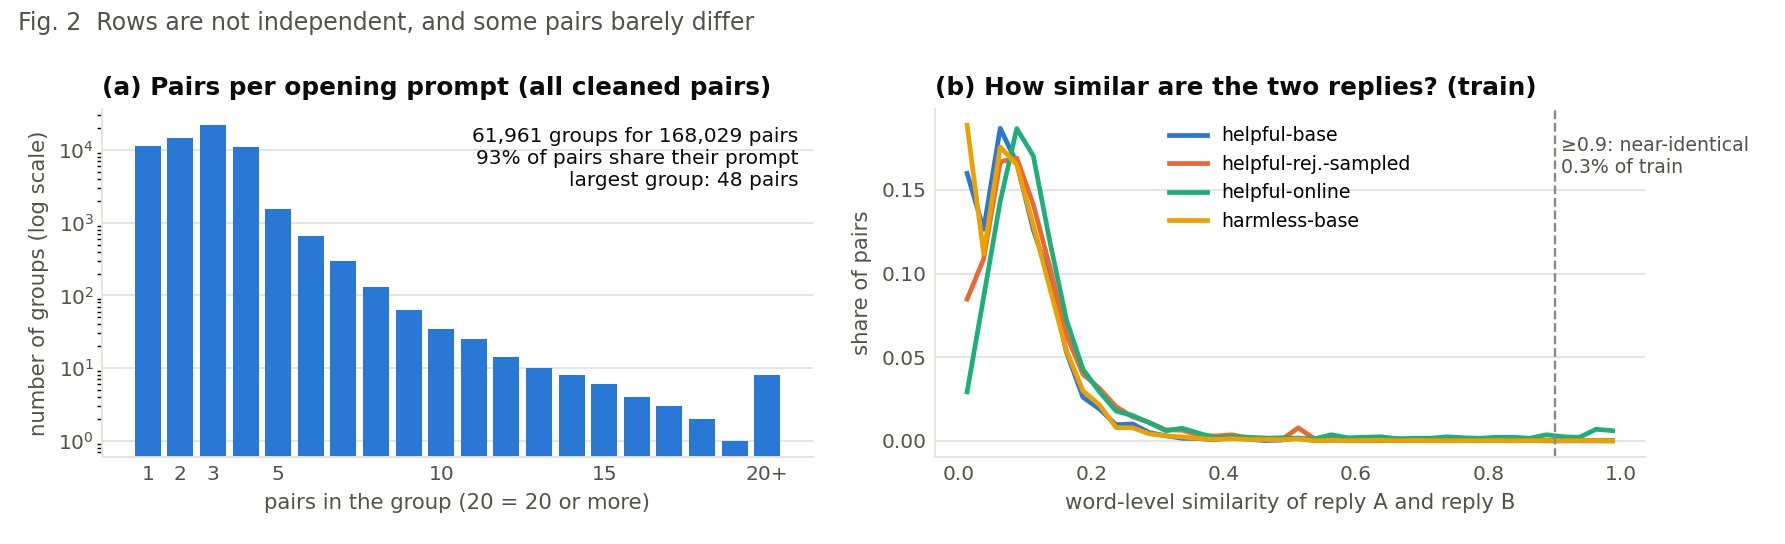

**fig3_length_distributions.png**

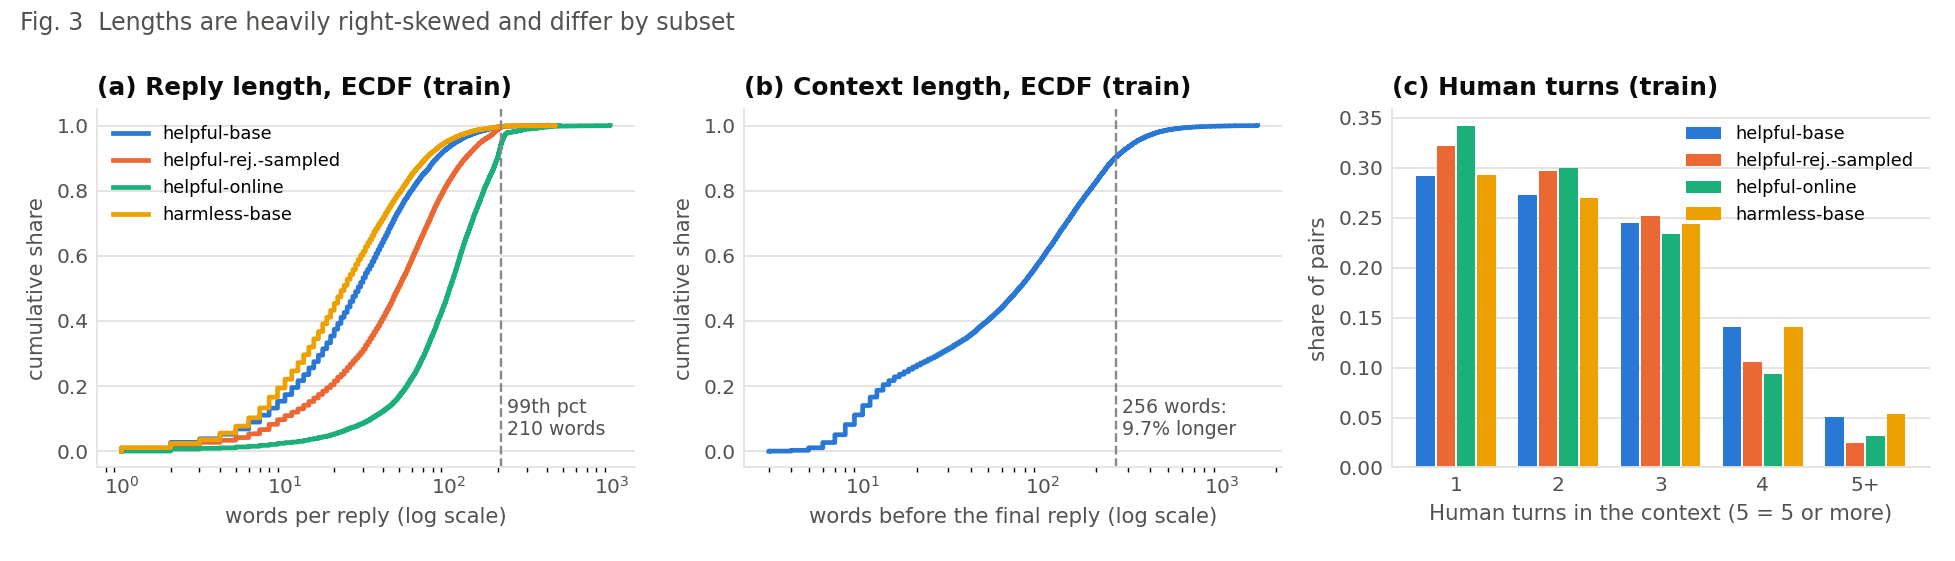

**fig4_length_bias.png**

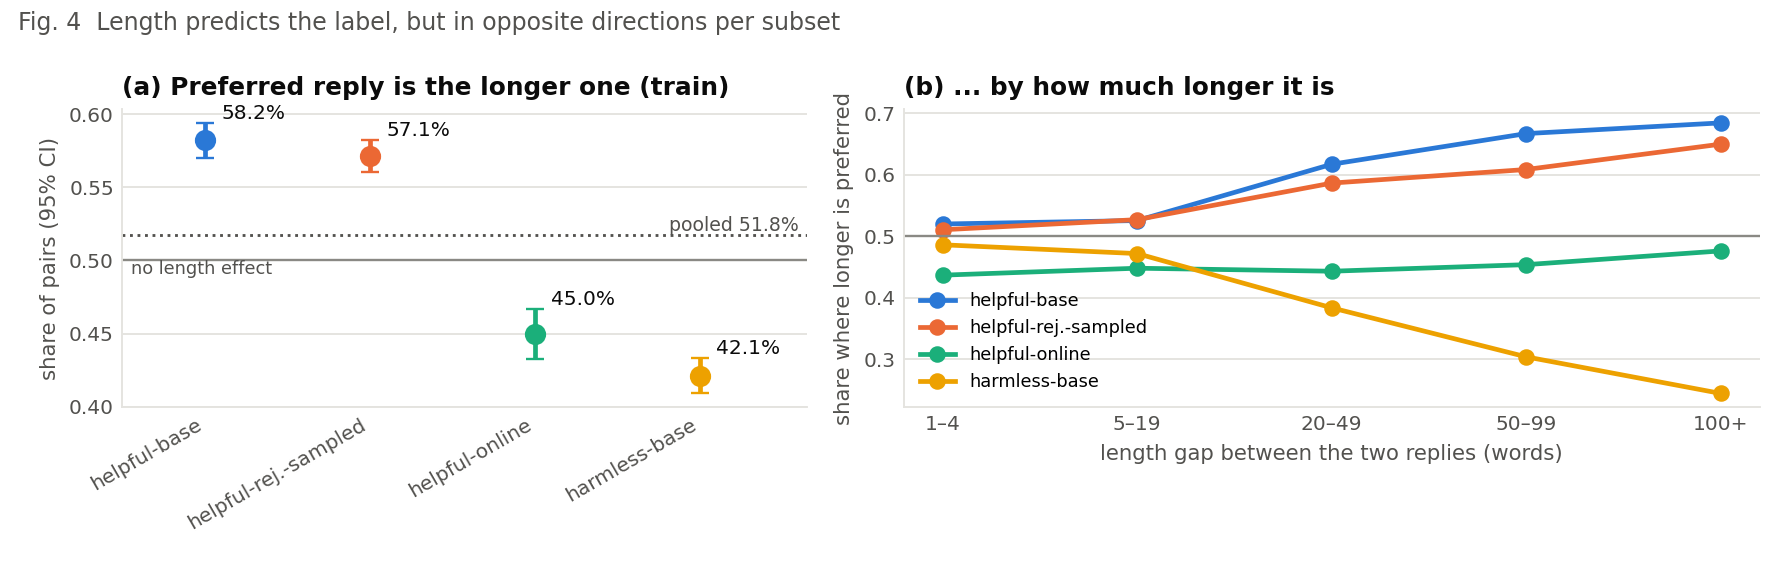

**fig5_length_baselines_dev.png**

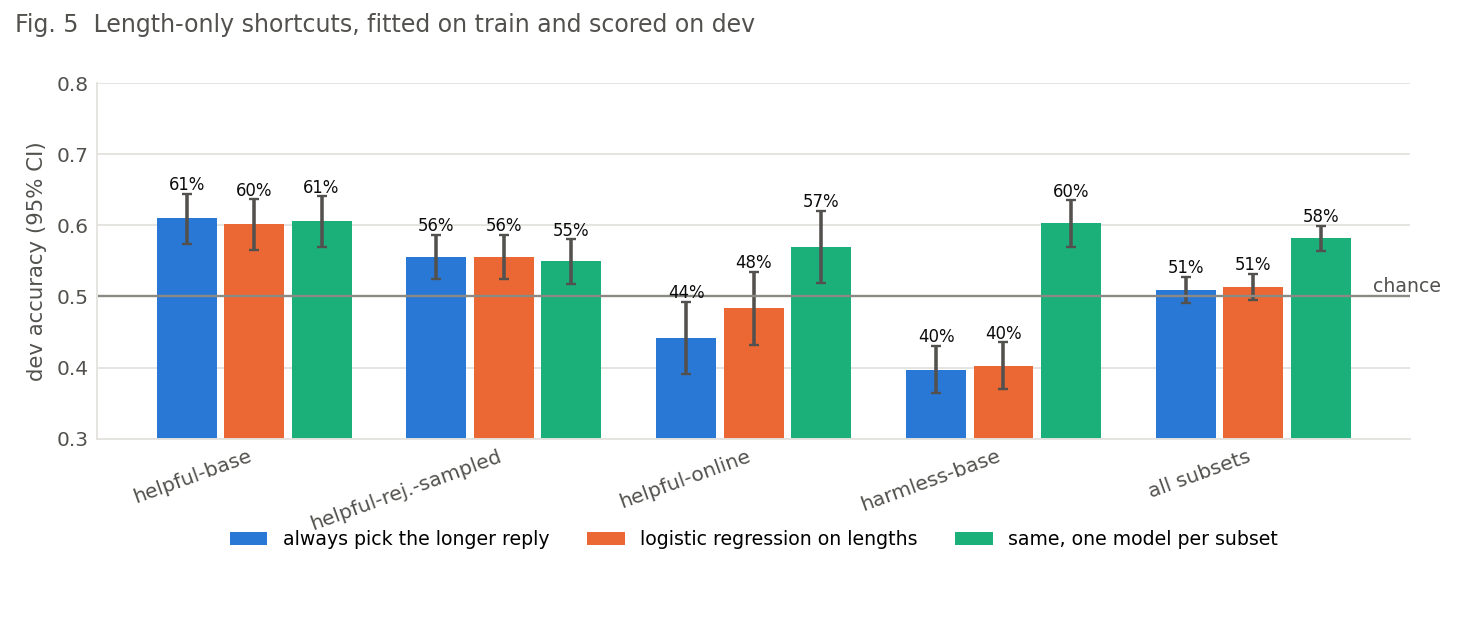

**fig6_refusals.png**

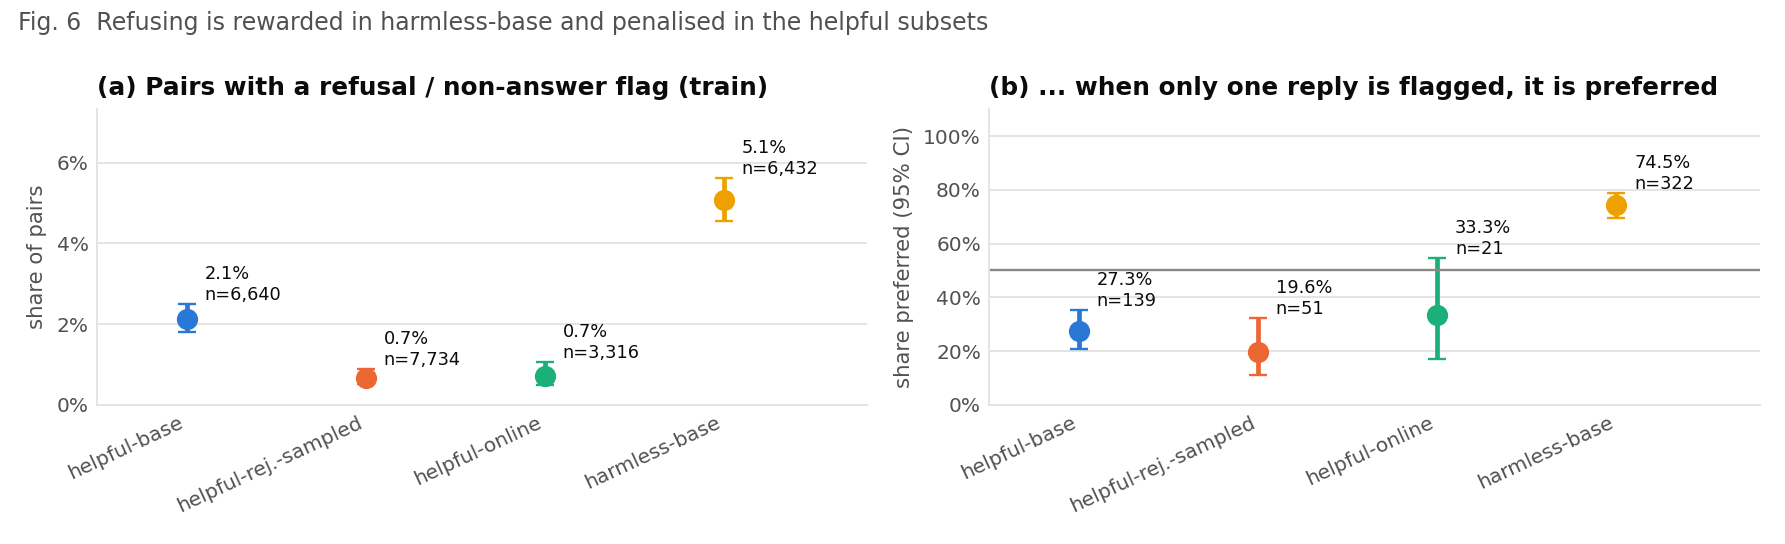

**fig7_feature_correlations.png**

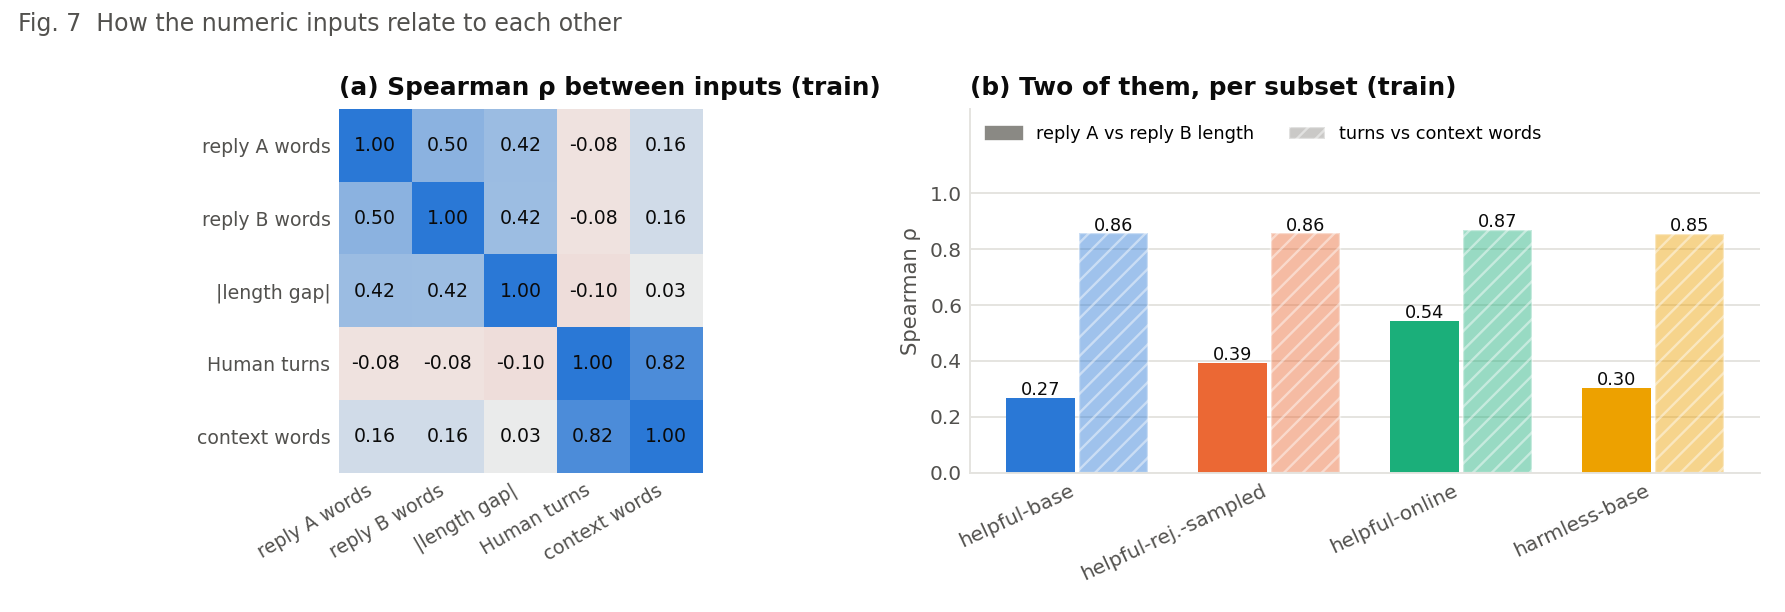

**fig8_inference.png**

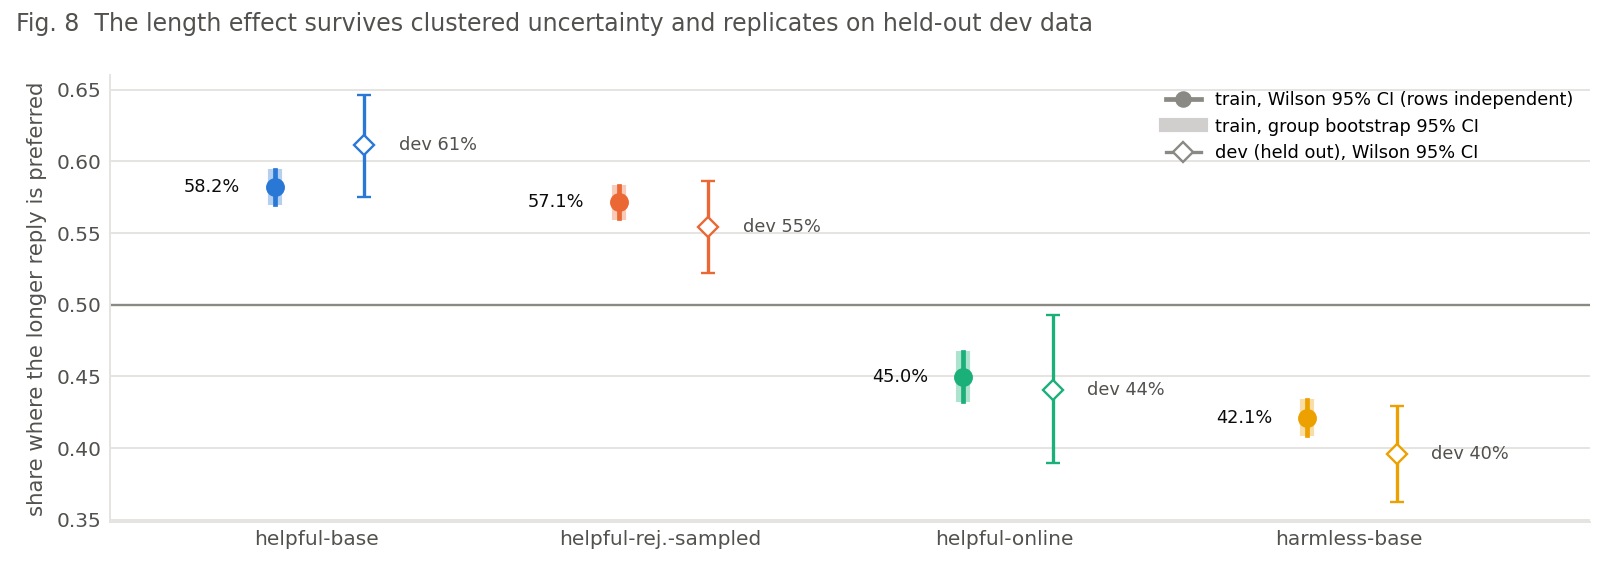

**fig9_cross_validation.png**

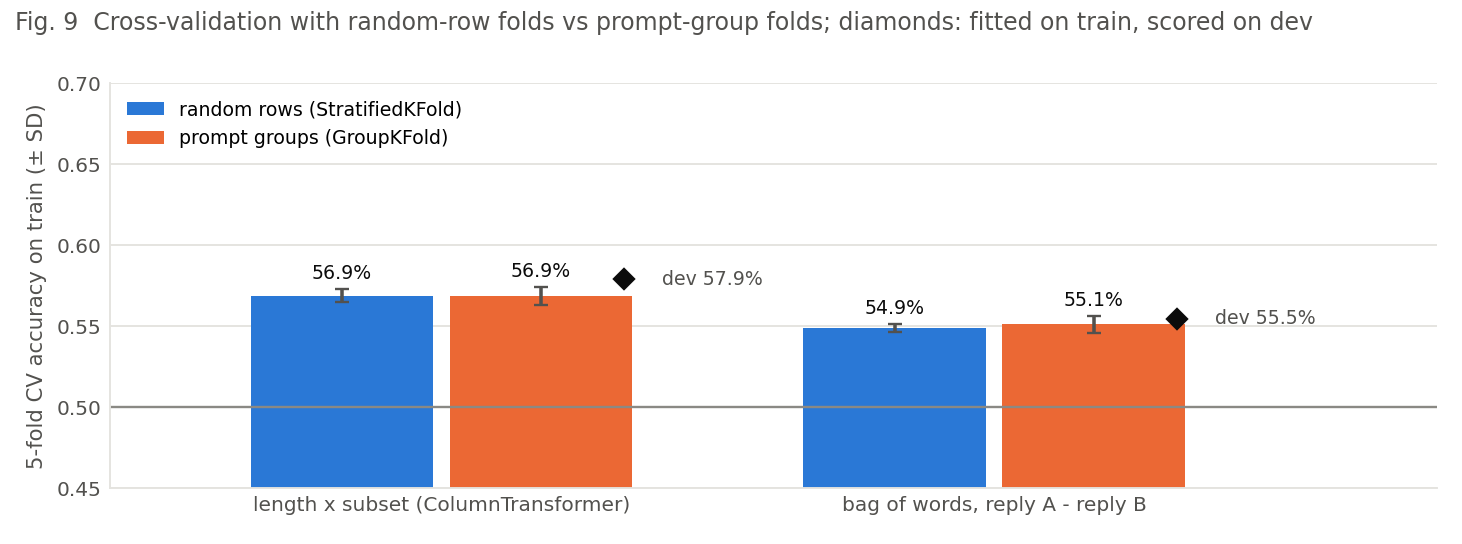

In [17]:
# Show the 9 EDA figures here, so a reviewer can read the analysis in the notebook.
# The interpretation of each figure is in docs/eda/findings.csv (above) and in the report, section 4.
import glob
from IPython.display import Image, Markdown, display
for path in sorted(glob.glob('docs/eda/fig*.png')):
    display(Markdown(f'**{path.split("/")[-1]}**'))
    display(Image(filename=path, width=900))

In [19]:
# Download the EDA outputs and the manifest, to commit them to GitHub (they hold no dataset text).
import shutil
from google.colab import files
shutil.make_archive('m2_outputs', 'zip', '.', 'docs/eda')
files.download('m2_outputs.zip')
files.download('manifests/v1.1.json')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Sample queries
Example pandas queries on the stored train/dev data (also saved to `audit/<version>/sample_queries.json`).

In [20]:
# Example pandas queries on the stored train/dev files (reads them from the bucket).
# --show 2 also prints 2 example pairs. Output: gs://<bucket>/audit/<version>/sample_queries.json
!python -m src.sample_queries --show 2


== Q1_size_and_label_balance
       pairs  groups  label_1_share
split                              
dev     2876    1074         0.5170
train  24122    8894         0.4981

== Q2_subset_mix
subset  harmless-base  helpful-base  helpful-online  helpful-rejection-sampled
split                                                                         
dev            0.2889        0.2514          0.1238                     0.3359
train          0.2666        0.2753          0.1375                     0.3206

== Q3_num_turns
            share
num_turns        
1          0.3090
2          0.2837
3          0.2450
4          0.1233
5+         0.0390

== Q4_length_bias
                           pairs  share_preferred_is_longer
subset                                                     
harmless-base               7263                     0.4097
helpful-base                7363                     0.5748
helpful-online              3672                     0.4431
helpful-rejection-sampled   87

## Results at a glance

In [21]:
# Summary of the run, read from the manifest: rows dropped, poisoning screen, split sizes.
import json
import pandas as pd
m = json.load(open('manifests/v1.1.json'))['steps']
print('Rows dropped:', json.dumps(m['step3_clean']['rows_dropped'], indent=2))
print('Poison screen:', m['step4_quality_checks']['poison_screen'])
pd.DataFrame(m['step7_split']['splits']).T[['pairs', 'groups', 'label_1_share', 'long_outlier_share']]

Rows dropped: {
  "0_unparseable_json": 0,
  "1_malformed_or_missing": 11,
  "2_context_mismatch": 329,
  "4a_empty_response": 194,
  "4b_identical_responses": 788,
  "4c_identical_after_pii_mask": 1,
  "5_exact_duplicates": 0
}
Poison screen: {'flagged_ngrams': 0, 'flagged_pairs': 0, 'params': {'ngram': 8, 'min_pairs': 20, 'one_sided_ratio': 0.9, 'max_report': 200, '_comment': 'flag word n-grams occurring one-sidedly (chosen vs rejected) in >= min_pairs pairs'}}


,pairs,groups,label_1_share,long_outlier_share
train,24122,8894,0.4981,0.018
dev,2876,1074,0.517,0.0219
test,3004,1095,0.491,0.0196
future_f1,16516,6141,0.4962,0.019
future_f2,16652,6130,0.4999,0.0201


## Verify the buckets and read a file back

A last check, like Cell 8 of the GCS lab: list every file in the two buckets, then read `dev.parquet` straight from the bucket with pandas. Only a few non-text columns are shown, because the dataset contains harmful text.

In [22]:
# Final check, like Cell 8 of the GCS lab:
# 1) list every file in the main bucket and the holdout bucket, with its size;
# 2) read dev.parquet straight from the bucket with pandas (gcsfs handles gs:// paths).
# Text columns are not printed: the dataset contains harmful text.
import fsspec
import pandas as pd
from src.common import load_config, storage_roots, join

cfg = load_config()
version = cfg['dataset']['version']
main_root, holdout_root = storage_roots(cfg)   # gs://<bucket> and gs://<bucket>-holdout

# 1. List the files in both buckets
for root in [main_root, holdout_root]:
    fs, path = fsspec.core.url_to_fs(root)
    print(f'\n--- Files in {root} ---')
    for name, info in sorted(fs.find(path, detail=True).items()):
        print(f'  - {name} ({info["size"]:,} bytes)')

# 2. Read dev.parquet directly from the bucket
dev_path = join(main_root, 'processed', version, 'dev.parquet')
dev_df = pd.read_parquet(dev_path)
print(f'\n--- Read test ({dev_path}) ---')
print(f'Rows loaded: {len(dev_df):,}')   # 2,876 (same as v1.0)
display(dev_df[['pair_id', 'subset', 'num_turns', 'len_diff', 'label']].head(3))


--- Files in gs://bc-rlhf-reward-2026 ---
  - bc-rlhf-reward-2026/audit/v1.0/poison_flagged_pairs.csv (15 bytes)
  - bc-rlhf-reward-2026/audit/v1.0/poison_screen.csv (35 bytes)
  - bc-rlhf-reward-2026/audit/v1.0/quality_report.json (1,568 bytes)
  - bc-rlhf-reward-2026/audit/v1.0/sample_queries.json (1,840 bytes)
  - bc-rlhf-reward-2026/audit/v1.1/poison_flagged_pairs.csv (15 bytes)
  - bc-rlhf-reward-2026/audit/v1.1/poison_screen.csv (35 bytes)
  - bc-rlhf-reward-2026/audit/v1.1/quality_report.json (1,595 bytes)
  - bc-rlhf-reward-2026/audit/v1.1/reconciliation.json (1,979 bytes)
  - bc-rlhf-reward-2026/audit/v1.1/reply_openings_harmless_train.csv (957 bytes)
  - bc-rlhf-reward-2026/audit/v1.1/sample_queries.json (1,847 bytes)
  - bc-rlhf-reward-2026/audit/v1.1/validation_log.csv (6,785 bytes)
  - bc-rlhf-reward-2026/manifests/v1.0.json (9,442 bytes)
  - bc-rlhf-reward-2026/manifests/v1.1.json (15,349 bytes)
  - bc-rlhf-reward-2026/processed/v1.0/dev.parquet (2,314,823 bytes)
  - bc-

,pair_id,subset,num_turns,len_diff,label
0,000a93401bd724692ac0839aa13c7b5acf9af7a6789a469653796960a1ed4df8,harmless-base,3,13,0
1,0065d435a6c02c5adc9477c97274c7ecd3dcb10eb6b823f55789983f320f0107,harmless-base,2,-12,1
2,0067d85664b711ff94720fb86da977bbd8afb1dbf70aa0bc409e04420be76d89,helpful-online,2,102,1


## Human review (can be done later)
Download the sheet, fill `my_choice` with A / B / tie, upload it back to `repo/audit/` with the Colab file browser, then run the scoring cell.
⚠️ Do not put this CSV on GitHub: it contains dataset text (it is git-ignored).

In [ ]:
# Download the review sheet to fill in by hand (my_choice = A / B / tie).
# It contains dataset text: keep it on your computer, never on GitHub.
from google.colab import files
files.download('audit/label_review_v1.1.csv')

In [ ]:
# After uploading the filled sheet back to audit/: score it against the crowdworkers' labels
# and download the updated manifest.
from google.colab import files
!python -m src.score_review
files.download('manifests/v1.1.json')